# 03 - Modelling
Rolling-origin backtest: 13 consecutive 28-day folds (one year). Training uses only data before each cutoff. Run `python -m src.models.train` to regenerate `fact_forecast`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 160
from src.config import connect, SCHEMA
con = connect(read_only=True)

In [2]:
from src.models.predict import model_comparison
model_comparison(con)

,wape,bias,mae,improvement_vs_naive
model_name,,,,
seasonal_naive,0.931,0.012,2.032,0.000
moving_avg_28,0.706,-0.001,1.540,0.242
ets_holt_winters,0.703,0.002,1.534,0.245
lightgbm_base,0.678,-0.006,1.479,0.272
lightgbm,0.677,-0.007,1.478,0.273


## Per-fold stability

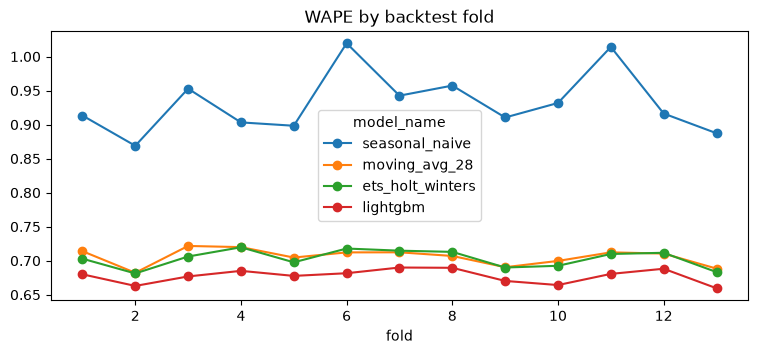

LightGBM beats moving average in 13 of 13 folds


In [3]:
from src.evaluation.metrics import summarise
df = con.execute(f"select * from {SCHEMA}.fact_forecast").df()
t = summarise(df, ['model_name','fold']).pivot(index='fold', columns='model_name', values='wape')
t[['seasonal_naive','moving_avg_28','ets_holt_winters','lightgbm']].plot(figsize=(9,3.5), marker='o', title='WAPE by backtest fold'); plt.show()
print('LightGBM beats moving average in', int((t.lightgbm < t.moving_avg_28).sum()), 'of', len(t), 'folds')

## Accuracy by forecast horizon day

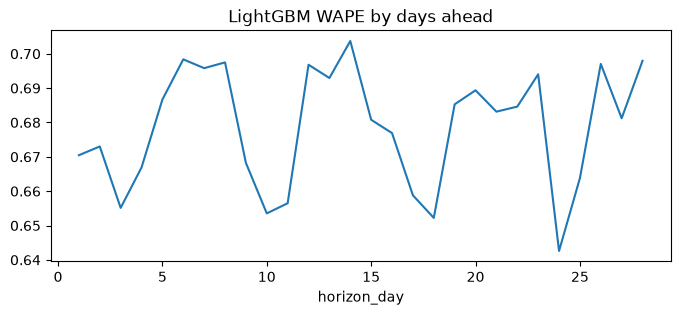

In [4]:
h = summarise(df[df.model_name=='lightgbm'], ['horizon_day'])
h.set_index('horizon_day').wape.plot(figsize=(8,3), title='LightGBM WAPE by days ahead'); plt.show()